# OAMe–G2: guest unbinding, dry and wet routes

95 reactive unbinding trajectories of 4-cyanobenzoate (G2) from octa-acid methyl (OAMe); on the wet route the
cavity entrance hydrates as the guest leaves, on the dry route it does not (49 dry, 46 wet).

* **Solute-only map**: guest + host coordinates.
* **Map with water**: guest + host + the K = 32 water oxygens that come closest to the complex at any frame,
  matched between every pair of trajectories by the Hungarian assignment.

Both use the L² distance, σ = median, α = 0. The solute-only map is explained with guest-geometry descriptors,
the map with water with the water coordinations d1–d12 and the guest orientation cos θ.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parents[1]          # repository root (notebook lives in systems/<name>/)
sys.path[:0] = [str(ROOT), str(Path.cwd())]
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathfdm import embed
from pathfdm.features import feature_matrix
from pathfdm.surrogate import fit_surrogate
from pathfdm.evaluation import auc_per_coordinate, kmeans_ari, align_signs, compare_embeddings
from pathfdm.plotting import apply_style, plot_space, plot_parity, plot_beeswarm, plot_paths, plot_binned, top_descriptor
import load_data as D
apply_style()
N_JOBS = 8

## Load (solute + 32 waters)

In [2]:
ts, labels = D.load(k_waters=32, n_jobs=N_JOBS)
sol = ts.solute_only()
print(f"{(labels == 1).sum()} dry, {(labels == 0).sum()} wet")

/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:171: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"
/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:171: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"
/home/shaheerah/

/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/GRO.py:245: UserWarning: Empty box [0., 0., 0.] found - treating as missing unit cell. Dimensions set to `None`.
  warnings.warn(wmsg)
/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:171: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"
/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/GRO.py:245: UserWarning: Empty box [0., 0., 0.] found - treating as missing unit cell. Dimensions set to `None`.
  warnings.warn(wmsg)
/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3

95 trajectories | 211 solute atoms + 32 water oxygens | 23-405 frames | 729 coordinates per frame
49 dry, 46 wet


## FDM embeddings: solute only, with water (matched), with water (not matched)

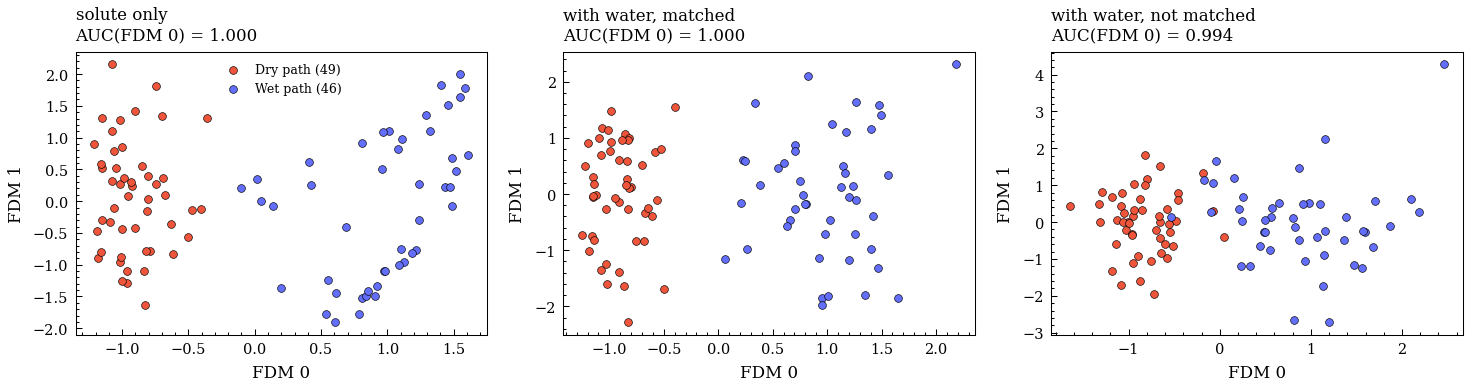

Spearman rho of FDM 0, solute only vs with water: [0.954]
with vs without matching, FDM 0-2: [ 0.852 -0.087  0.071]


,AUC FDM 0,k-means ARI (FDM 0-1)
solute only,1.000,0.876
"with water, matched",1.000,1.000
"with water, not matched",0.994,0.688


In [3]:
Z_sol = embed(sol.fd, metric="l2", n_jobs=N_JOBS)
Z_w = embed(ts.fd, metric="l2", water=True, water_match="dtw", n_jobs=N_JOBS)
Z_nm = align_signs(embed(ts.fd, metric="l2", water=False, n_jobs=N_JOBS), Z_w)
maps = {"solute only": Z_sol, "with water, matched": Z_w, "with water, not matched": Z_nm}
fig, axs = plt.subplots(1, 3, figsize=(10, 2.8))
for ax, (name, Z) in zip(axs, maps.items()):
    plot_space(Z, labels, D.LABEL_CONFIG, ax=ax, title=f"{name}\nAUC(FDM 0) = {auc_per_coordinate(Z, labels)[0]:.3f}",
               legend=ax is axs[0])
plt.tight_layout(); plt.show()
print("Spearman rho of FDM 0, solute only vs with water:", np.round(compare_embeddings(Z_sol, Z_w, 1), 3))
print("with vs without matching, FDM 0-2:", np.round(compare_embeddings(Z_nm, Z_w, 3), 3))
pd.DataFrame({n: {"AUC FDM 0": auc_per_coordinate(Z, labels)[0], "k-means ARI (FDM 0-1)": kmeans_ari(Z, labels)}
              for n, Z in maps.items()}).T.round(3)

## Surrogate models

The surrogate is an ExtraTrees regressor (500 trees) predicting FDM 0 from the standardized
descriptors. **Out-of-bag R²**: each trajectory predicted by the trees that did not see it. **Cross-validation**:
5-fold, repeated 5 times; R² is the mean ± sd over the 25 folds, and the parity plot shows the mean of the five
held-out predictions of every trajectory. The beeswarm shows the SHAP value of each descriptor for every
trajectory (colour = descriptor value).

In [4]:
X_w, n_w = feature_matrix(D.water_map_descriptors(ts), D.WATER_MAP_NAMES)
res_w = fit_surrogate(X_w, Z_w[:, 0], n_w)
X_g, n_g = feature_matrix(D.guest_descriptors(ts), D.GUEST_NAMES)
res_s = fit_surrogate(X_g, Z_sol[:, 0], n_g)
print("map with water   (52: d1-d12, cos theta):  ", res_w.summary())
print("solute-only map  (32 guest descriptors):    ", res_s.summary())
pd.concat({"with water": res_w.table(6), "solute only": res_s.table(6)}, axis=1).round(3)

map with water   (52: d1-d12, cos theta):   52 descriptors | out-of-bag R2 = 0.949 | 5-fold CV x 5: R2 = 0.942 +/- 0.026
solute-only map  (32 guest descriptors):     32 descriptors | out-of-bag R2 = 0.749 | 5-fold CV x 5: R2 = 0.716 +/- 0.091


with water                              \
                   feature shap_share frac_folds_rank1   
0          $\Delta(d_{6})$      0.172             0.12   
1          $\sigma(d_{6})$      0.151             0.88   
2          $\sigma(d_{7})$      0.130             0.00   
3  $\langle d_{8} \rangle$      0.071             0.00   
4  $\langle d_{7} \rangle$      0.063             0.00   
5          $\sigma(d_{5})$      0.063             0.00   

                    solute only                              
                        feature shap_share frac_folds_rank1  
0  $\langle \cos\theta \rangle$      0.221              1.0  
1       $\langle |n_z| \rangle$      0.109              0.0  
2                   $\sigma(r)$      0.105              0.0  
3  $\langle \tau_{COO} \rangle$      0.084              0.0  
4                   $\sigma(x)$      0.068              0.0  
5                 $\sigma(n_x)$      0.057              0.0

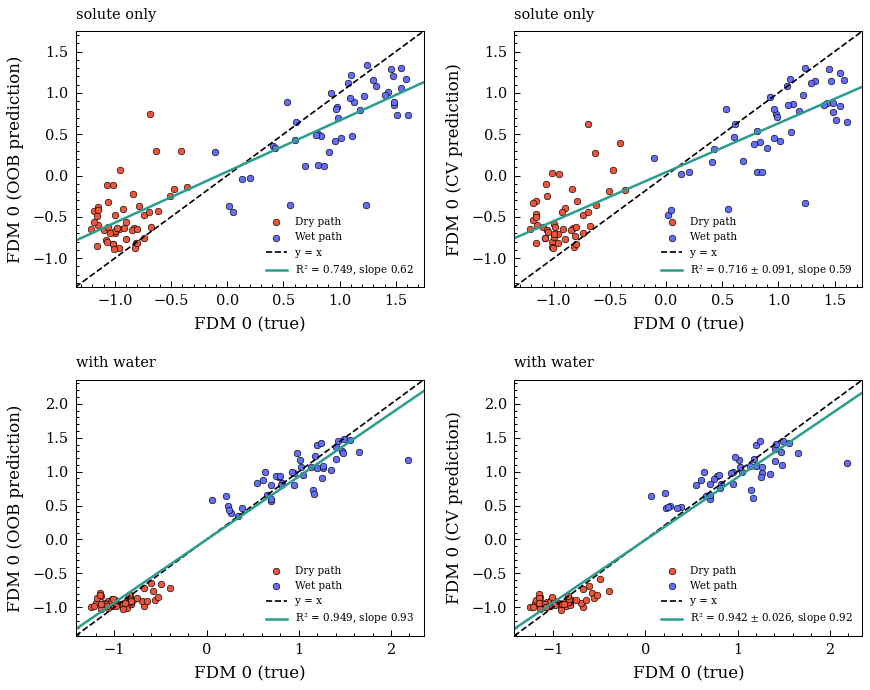

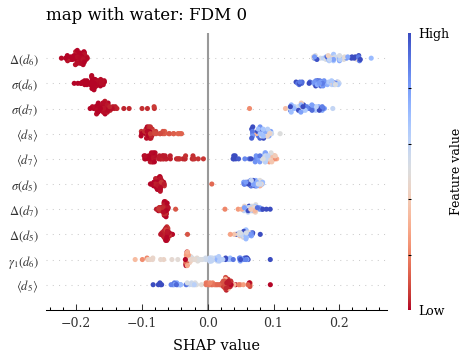

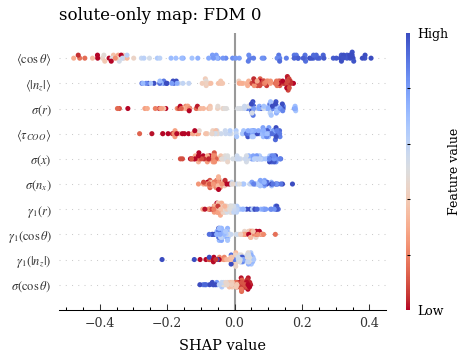

In [5]:
fig, axs = plt.subplots(2, 2, figsize=(6, 4.8))
plot_parity(res_s, labels, D.LABEL_CONFIG, axs=axs[0], title="solute only")
plot_parity(res_w, labels, D.LABEL_CONFIG, axs=axs[1], title="with water")
plt.tight_layout(); plt.show()
plot_beeswarm(res_w, max_display=10, title="map with water: FDM 0"); plt.show()
plot_beeswarm(res_s, max_display=10, title="solute-only map: FDM 0"); plt.show()

## Descriptors along the paths

As in the paper figure: (c) water coordination d<sub>6</sub> at V2 against the guest height cyl.z, one line
per trajectory; (f) guest orientation cos θ and (i) the number of waters in the host cavity as functions of
cyl.z, each trajectory averaged in 1 Å bins of cyl.z (median over trajectories and interquartile band). The
dashed line is cyl.z = 6 Å, the upper limit of the bound state. `DESC` (bottom right) plots any hydration or
guest descriptor the same way; by default the one behind the highest-ranked SHAP feature of the map with water.

The paper plots cos θ with the opposite sign (PLUMED convention of the earlier figure): set `COS_SIGN = -1`.

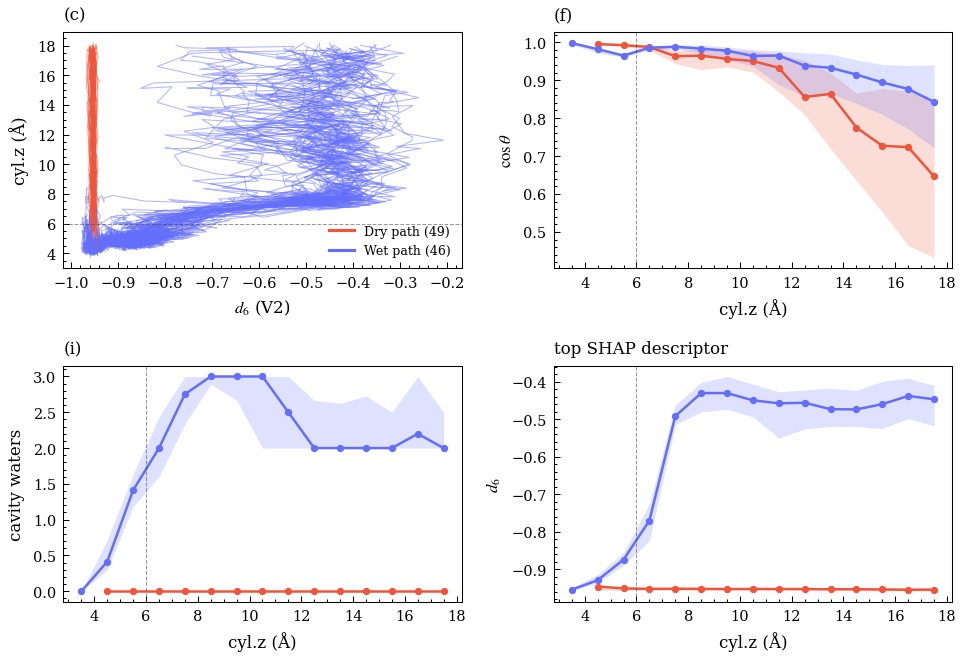

In [6]:
COS_SIGN = 1.0
EDGES = np.arange(-1, 19, 1.0)                     # 1 A bins of cyl.z
hyd, gst = D.hydration_descriptors(ts), D.guest_descriptors(ts)
cz = [D.cyl_z(c) for c in ts.coords]
cav = [D.cavity_waters(c, ts.water_info["n_solute_atoms"]) for c in ts.coords]
DESC = D.WATER_MAP_NAMES[top_descriptor(res_w, D.WATER_MAP_NAMES)]        # or e.g. "d_{6}", r"\cos\theta"
pool = {**{n: [h[:, i] for h in hyd] for i, n in enumerate(D.HYDRATION_NAMES)},
        **{n: [g[:, i] for g in gst] for i, n in enumerate(D.GUEST_NAMES)}}
fig, axs = plt.subplots(2, 2, figsize=(6.6, 4.6))
plot_paths([h[:, 5] for h in hyd], cz, labels, D.LABEL_CONFIG, ax=axs[0, 0], xlabel="$d_{6}$ (V2)",
           ylabel="cyl.z (Å)", lw=0.5, alpha=0.5, title="(c)")
plot_binned(cz, [COS_SIGN * g[:, 3] for g in gst], labels, D.LABEL_CONFIG, EDGES, ax=axs[0, 1], xlabel="cyl.z (Å)",
            ylabel=r"$\cos\theta$", legend=False, title="(f)")
_, cav_table = plot_binned(cz, cav, labels, D.LABEL_CONFIG, EDGES, ax=axs[1, 0], xlabel="cyl.z (Å)",
                           ylabel="cavity waters", legend=False, title="(i)")
plot_binned(cz, pool[DESC], labels, D.LABEL_CONFIG, EDGES, ax=axs[1, 1], xlabel="cyl.z (Å)", ylabel=f"${DESC}$",
            legend=False, title="top SHAP descriptor" if DESC == D.WATER_MAP_NAMES[top_descriptor(res_w, D.WATER_MAP_NAMES)] else None)
for ax in (axs[0, 1], axs[1, 0], axs[1, 1]):
    ax.axvline(D.BOUND_Z, color="#444444", lw=0.5, ls="--", alpha=0.55)
axs[0, 0].axhline(D.BOUND_Z, color="#444444", lw=0.5, ls="--", alpha=0.55)
plt.tight_layout(); plt.show()

## Setting: number of waters K, with and without matching

The waters are ranked by closest approach to the complex, so the K closest are the first K of the 64 loaded.
Without matching, waters are compared in this order.

95 trajectories | 211 solute atoms + 64 water oxygens | 23-405 frames | 825 coordinates per frame


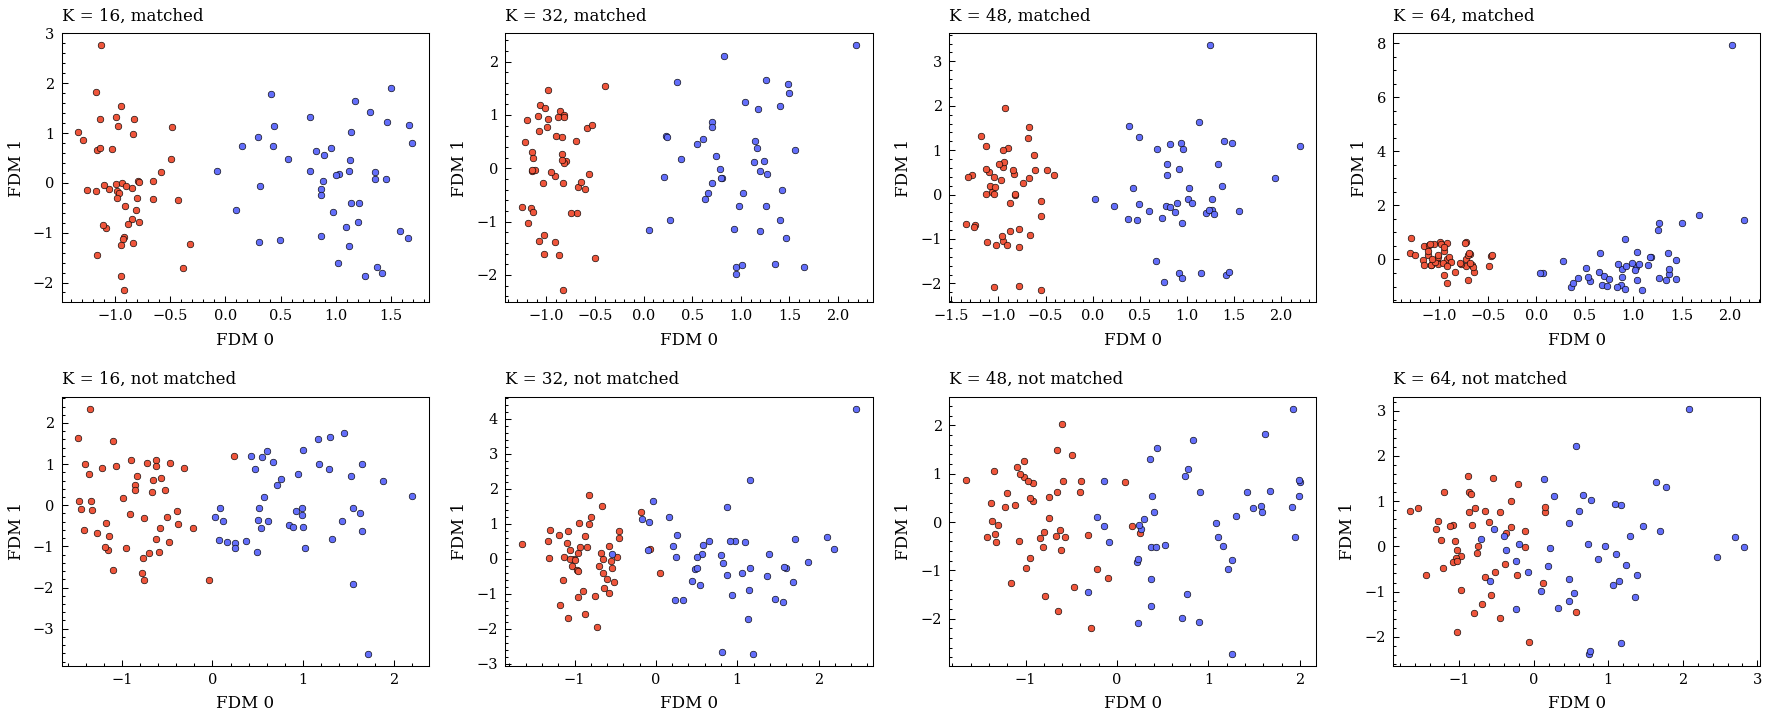

,K,waters,AUC FDM 0,k-means ARI,rho FDM 0 vs matched
0,16,matched,1.000,0.958,1.000
1,16,not matched,0.998,0.958,0.902
2,32,matched,1.000,1.000,1.000
3,32,not matched,0.994,0.688,0.852
4,48,matched,1.000,0.958,1.000
5,48,not matched,0.988,0.724,0.852
6,64,matched,1.000,1.000,1.000
7,64,not matched,0.944,0.463,0.802


In [7]:
ts64, _ = D.load(k_waters=64, n_jobs=N_JOBS)
rows, fig, axs = [], *plt.subplots(2, 4, figsize=(12, 5))
for col, K in enumerate([16, 32, 48, 64]):
    tk = ts64.first_k_waters(K)
    Zm = embed(tk.fd, metric="l2", water=True, water_match="dtw", n_jobs=N_JOBS)
    Zn = align_signs(embed(tk.fd, metric="l2", water=False, n_jobs=N_JOBS), Zm)
    for row, (kind, Z) in enumerate([("matched", Zm), ("not matched", Zn)]):
        plot_space(Z, labels, D.LABEL_CONFIG, ax=axs[row, col], title=f"K = {K}, {kind}", legend=False, s=10)
        rows.append({"K": K, "waters": kind, "AUC FDM 0": auc_per_coordinate(Z, labels)[0],
                     "k-means ARI": kmeans_ari(Z, labels), "rho FDM 0 vs matched": compare_embeddings(Z, Zm, 1)[0]})
plt.tight_layout(); plt.show()
pd.DataFrame(rows).round(3)

## Setting: maps without the host

The guest alone, and the guest with the 32 waters that come closest to the guest (matched).

95 trajectories | 15 solute atoms + 32 water oxygens | 23-405 frames | 141 coordinates per frame


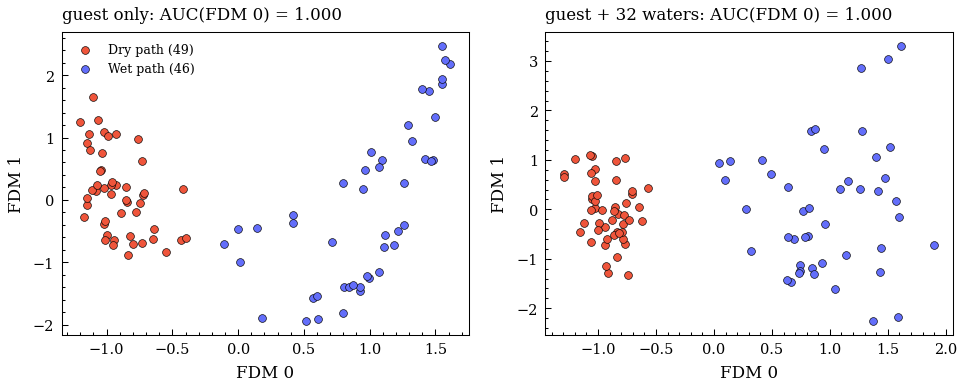

In [8]:
tg, _ = D.load(k_waters=32, solute_sel=D.GUEST_SEL, n_jobs=N_JOBS)
Z_g = embed(tg.solute_only().fd, metric="l2", n_jobs=N_JOBS)
Z_gw = embed(tg.fd, metric="l2", water=True, water_match="dtw", n_jobs=N_JOBS)
fig, axs = plt.subplots(1, 2, figsize=(6.6, 2.8))
for ax, (name, Z) in zip(axs, {"guest only": Z_g, "guest + 32 waters": Z_gw}.items()):
    plot_space(Z, labels, D.LABEL_CONFIG, ax=ax, title=f"{name}: AUC(FDM 0) = {auc_per_coordinate(Z, labels)[0]:.3f}",
               legend=ax is axs[0])
plt.tight_layout(); plt.show()